# 🧠 Custom Components for Multi-Class Classification
This notebook demonstrates three advanced customization techniques in TensorFlow/Keras:

1. **CustomLabel-Smoothed Categorical Crossentropy Loss** – improves generalization by softening hard labels.
2. **Per-Class Evaluation Metrics** – tracks precision, recall, and F1-score for each class during training.
3. **Custom EarlyStopping Callback** – monitors validation **macro F1-score** (not just loss/accuracy) to stop training early.

✅ All components are **graph-safe** and avoid common `tf.function` pitfalls like:
- `InaccessibleTensorError`
- `AttributeError: 'CustomCallback' object has no attribute 'validation_data'`

We use a synthetic imbalanced 4-class dataset to showcase real-world applicability.

In [ ]:
# Install required packages (quiet mode)
!pip install -q tensorflow scikit-learn

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, f1_score

print(f"TensorFlow version: {tf.__version__}")

TensorFlow version: 2.19.0


## 📊 Step 1: Generate Synthetic Multi-Class Dataset

We create an imbalanced 4-class classification problem with 30 features:
- 40% of samples belong to Class 0
- 30% to Class 1
- 20% to Class 2
- 10% to Class 3

This imbalance makes the task more realistic and highlights the need for robust metrics and loss functions.

In [ ]:
# Generate imbalanced multi-class dataset (4 classes)
X, y = make_classification(
    n_samples=6000,
    n_features=30,
    n_informative=20,
    n_redundant=10,
    n_classes=4,
    n_clusters_per_class=1,
    weights=[0.4, 0.3, 0.2, 0.1],  # Imbalanced class distribution
    random_state=42
)

# Split into train/test (stratified to preserve class ratios)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Standardize features (mean=0, std=1)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Convert integer labels to one-hot encoded vectors
num_classes = 4
y_train_cat = keras.utils.to_categorical(y_train, num_classes)
y_test_cat = keras.utils.to_categorical(y_test, num_classes)

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")
print(f"Class distribution (train): {np.bincount(y_train)}")

Train shape: (4800, 30), Test shape: (1200, 30)
Class distribution (train): [1922 1431  960  487]


## 🔥 Step 2: Custom Loss Function — Label-Smoothed Categorical Crossentropy (Graph-Safe)

### Why Label Smoothing?
Standard crossentropy uses **hard labels** like `[0, 0, 1, 0]`. This can cause overfitting and overconfident predictions.

**Label smoothing** replaces hard labels with **soft targets**:

For a 4-class problem with smoothing factor `ε = 0.1`:
- True class: `1 - ε = 0.9`
- Other classes: `ε / K = 0.1 / 4 = 0.025`

So `[0, 0, 1, 0]` becomes `[0.025, 0.025, 0.925, 0.025]`.

We **pass `num_classes` as a Python int** (not inferred from tensor shape) to avoid `InaccessibleTensorError`.
This ensures full compatibility with `tf.function` and Keras graph tracing.

In [ ]:
class LabelSmoothingCrossentropy(keras.losses.Loss):
    """
    Graph-safe label-smoothed categorical crossentropy.

    Parameters:
        num_classes (int): Number of classes (must be known at compile time).
        smoothing (float): Smoothing factor in [0, 1). Default: 0.1.

    Formula:
        smoothed_label = y_true * (1 - ε) + ε / K
        loss = categorical_crossentropy(smoothed_label, y_pred)
    """
    def __init__(self, num_classes, smoothing=0.1, name="label_smoothing_crossentropy"):
        super().__init__(name=name)
        self.num_classes = num_classes          # Python int (safe!)
        self.smoothing = smoothing              # Python float (safe!)

    def call(self, y_true, y_pred):
        # Compute smoothed labels using only input tensors and Python scalars
        smoothed_labels = y_true * (1.0 - self.smoothing) + self.smoothing / self.num_classes

        # Compute standard categorical crossentropy
        loss = tf.keras.losses.categorical_crossentropy(smoothed_labels, y_pred, from_logits=False)

        # Return mean loss across batch
        return tf.reduce_mean(loss)

# 🔍 Quick test
y_true_test = tf.constant([[1.0, 0.0, 0.0, 0.0]])
y_pred_test = tf.constant([[0.8, 0.1, 0.05, 0.05]])
ls_loss_fn = LabelSmoothingCrossentropy(num_classes=4, smoothing=0.1)
test_loss = ls_loss_fn(y_true_test, y_pred_test)
print(f"Label-smoothed loss (smoothing=0.1): {test_loss.numpy():.4f}")

Label-smoothed loss (smoothing=0.1): 0.4138


## 📏 Step 3: Custom Metrics — Per-Class Precision, Recall, F1

Standard `accuracy` hides performance on minority classes. We implement a **custom metric** that tracks:
- **True Positives (TP)**
- **False Positives (FP)**
- **False Negatives (FN)**

Then computes per-class:
- **Precision = TP / (TP + FP)**
- **Recall = TP / (TP + FN)**
- **F1 = 2 × (Precision × Recall) / (Precision + Recall)**

In [ ]:
class PerClassMetrics(keras.metrics.Metric):
    def __init__(self, num_classes, name="per_class_metrics", **kwargs):
        super().__init__(name=name, **kwargs)
        self.num_classes = num_classes

        # Create state variables (one per class)
        self.true_positives = self.add_weight(
            name="tp", shape=(num_classes,), initializer="zeros", dtype=tf.float32
        )
        self.false_positives = self.add_weight(
            name="fp", shape=(num_classes,), initializer="zeros", dtype=tf.float32
        )
        self.false_negatives = self.add_weight(
            name="fn", shape=(num_classes,), initializer="zeros", dtype=tf.float32
        )

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_true_class = tf.argmax(y_true, axis=1)
        y_pred_class = tf.argmax(y_pred, axis=1)

        y_true_oh = tf.one_hot(y_true_class, depth=self.num_classes, dtype=tf.float32)
        y_pred_oh = tf.one_hot(y_pred_class, depth=self.num_classes, dtype=tf.float32)

        tp = tf.reduce_sum(y_true_oh * y_pred_oh, axis=0)
        fp = tf.reduce_sum((1 - y_true_oh) * y_pred_oh, axis=0)
        fn = tf.reduce_sum(y_true_oh * (1 - y_pred_oh), axis=0)

        self.true_positives.assign_add(tp)
        self.false_positives.assign_add(fp)
        self.false_negatives.assign_add(fn)

    def result(self):
        precision = tf.math.divide_no_nan(
            self.true_positives,
            self.true_positives + self.false_positives
        )
        recall = tf.math.divide_no_nan(
            self.true_positives,
            self.true_positives + self.false_negatives
        )
        f1 = tf.math.divide_no_nan(
            2 * precision * recall,
            precision + recall
        )
        return {
            "precision": precision,
            "recall": recall,
            "f1_score": f1
        }

    def reset_state(self):
        self.true_positives.assign(tf.zeros_like(self.true_positives))
        self.false_positives.assign(tf.zeros_like(self.false_positives))
        self.false_negatives.assign(tf.zeros_like(self.false_negatives))

## ⏹️ Step 4: Custom Callback — Early Stopping Based on Macro F1

Standard `EarlyStopping` monitors loss or accuracy, which can be misleading for imbalanced data.

Our custom callback:
1. Computes **macro F1-score** on validation set after each epoch
2. Tracks the best F1 seen so far
3. Stops training if no improvement for `patience` epochs
4. Restores best weights

✅ **Key Fix**: We **explicitly pass `validation_data`** to avoid `AttributeError`.

In [ ]:
class CustomEarlyStopping(keras.callbacks.Callback):
    def __init__(self, validation_data, patience=5, min_delta=0.001):
        super().__init__()
        self.validation_data = validation_data  # ✅ Explicitly stored
        self.patience = patience
        self.min_delta = min_delta
        self.best_f1 = -np.inf
        self.wait = 0
        self.stopped_epoch = 0
        self.best_weights = None

    def on_epoch_end(self, epoch, logs=None):
        val_x, val_y = self.validation_data

        # Predict on validation set
        val_preds = self.model.predict(val_x, verbose=0)

        pred_classes = np.argmax(val_preds, axis=1)
        true_classes = np.argmax(val_y, axis=1)

        val_f1 = f1_score(true_classes, pred_classes, average='macro')

        print(f"\nEpoch {epoch+1} - Val Macro F1: {val_f1:.4f}")

        if val_f1 > self.best_f1 + self.min_delta:
            self.best_f1 = val_f1
            self.wait = 0
            self.best_weights = self.model.get_weights()
        else:
            self.wait += 1
            if self.wait >= self.patience:
                self.stopped_epoch = epoch
                self.model.stop_training = True
                print(f"\n🛑 Early stopping triggered at epoch {epoch+1}!")

    def on_train_end(self, logs=None):
        if self.stopped_epoch > 0:
            print(f"✅ Restoring best weights from epoch {self.stopped_epoch - self.patience + 1}")
            self.model.set_weights(self.best_weights)

## 🚀 Step 5: Build and Train the Model

We build a simple feedforward neural network:
- Input: 30 features
- Hidden layers: 128 → 64 neurons (ReLU + Dropout)
- Output: 4 neurons (softmax)

Compile with:
- **Optimizer**: Adam
- **Loss**: Our custom `LabelSmoothingCrossentropy` (with `num_classes=4`)
- **Metrics**: Accuracy + `PerClassMetrics`

Train with:
- Batch size: 64
- Max epochs: 50
- Callbacks: `CustomEarlyStopping` + `ReduceLROnPlateau`

In [ ]:
# Prepare validation data tuple
val_data = (X_test, y_test_cat)

# Build model
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

# Compile with custom components
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=LabelSmoothingCrossentropy(num_classes=num_classes, smoothing=0.1),
    metrics=['accuracy', PerClassMetrics(num_classes)]
)

# Train model
history = model.fit(
    X_train, y_train_cat,
    batch_size=64,
    epochs=50,
    validation_data=val_data,
    callbacks=[
        CustomEarlyStopping(validation_data=val_data, patience=5),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
    ],
    verbose=1
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
71/75 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.4914 - f1_score: 0.4070 - loss: 1.2129 - precision: 0.4114 - recall: 0.4159
Epoch 1 - Val Macro F1: 0.7748
75/75 ━━━━━━━━━━━━━━━━━━━━ 15s 82ms/step - accuracy: 0.5022 - f1_score: 0.4166 - loss: 1.1984 - precision: 0.4217 - recall: 0.4251 - val_accuracy: 0.8667 - val_f1_score: 0.7748 - val_loss: 0.6475 - val_precision: 0.8756 - val_recall: 0.7639 - learning_rate: 0.0010
Epoch 2/50
68/75 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8344 - f1_score: 0.7685 - loss: 0.7138 - precision: 0.8254 - recall: 0.7536
Epoch 2 - Val Macro F1: 0.9080
75/75 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8359 - f1_score: 0.7709 - loss: 0.7107 - precision: 0.8254 - recall: 0.7561 - val_accuracy: 0.9325 - val_f1_score: 0.9080 - val_loss: 0.5463 - val_precision: 0.9274 - val_recall: 0.8944 - learning_rate: 0.0010
Epoch 3/50
74/75 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8905 - f1_score: 0.8552 - loss: 0.6221 - precision: 0.8685 - reca

## 📈 Step 6: Final Evaluation and Visualization

After training, we:
1. Evaluate on test set
2. Print per-class metrics
3. Show full classification report
4. Plot training history

38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step 

✅ Test Accuracy: 0.9917
Class 0 - Precision: 0.992, Recall: 0.994, F1: 0.993
Class 1 - Precision: 0.986, Recall: 1.000, F1: 0.993
Class 2 - Precision: 0.996, Recall: 0.988, F1: 0.992
Class 3 - Precision: 1.000, Recall: 0.967, F1: 0.983

📋 Detailed Classification Report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       480
           1       0.99      1.00      0.99       358
           2       1.00      0.99      0.99       240
           3       1.00      0.97      0.98       122

    accuracy                           0.99      1200
   macro avg       0.99      0.99      0.99      1200
weighted avg       0.99      0.99      0.99      1200



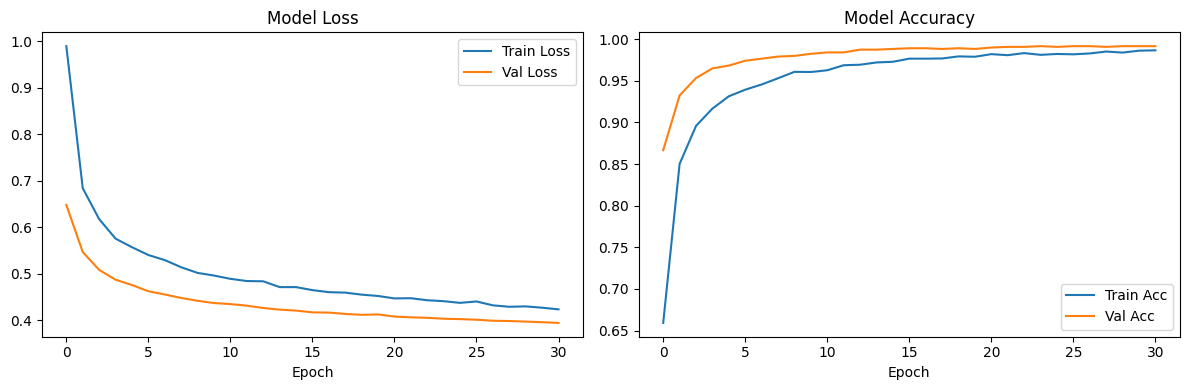

In [ ]:
# Final evaluation using predictions (robust and clear)
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

# Compute accuracy
test_acc = np.mean(y_pred_classes == y_test)
print(f"\n✅ Test Accuracy: {test_acc:.4f}")

# Compute per-class metrics
from sklearn.metrics import precision_recall_fscore_support
precision, recall, f1, support = precision_recall_fscore_support(
    y_test, y_pred_classes, average=None, labels=range(num_classes)
)

# Print per-class results
for i in range(num_classes):
    print(f"Class {i} - Precision: {precision[i]:.3f}, "
          f"Recall: {recall[i]:.3f}, "
          f"F1: {f1[i]:.3f}")

# Full report
print("\n📋 Detailed Classification Report:")
print(classification_report(y_test, y_pred_classes, zero_division=0))

# Plot training history
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

# ✅ Step-by-Step: Implement a Graph-Safe Custom Loss Function in TensorFlow/Keras

To avoid `InaccessibleTensorError` and ensure compatibility with `tf.function`, follow these **graph-safe practices** when implementing a custom loss function.

## 🚫 Common Pitfall (Unsafe)

```python
# ❌ DANGEROUS: Infers num_classes from tensor shape inside call()
class UnsafeLoss(keras.losses.Loss):
    def __init__(self, smoothing=0.1):
        super().__init__()
        self.smoothing = smoothing
        self.num_classes = None  # Will store a Tensor later → ERROR!

    def call(self, y_true, y_pred):
        if self.num_raises is None:
            # ⚠️ Creates a tensor inside tf.function graph
            self.num_classes = tf.cast(tf.shape(y_true)[-1], tf.float32)  # ❌ LEAKS TENSOR!
        ...
```

This causes:
> `InaccessibleTensorError: ... is out of scope and cannot be used here.`

Because **tensors created inside one `tf.function` graph cannot be reused in another**.

## ✅ Safe Implementation Steps

### Step 1: **Pass all necessary metadata as Python values**
Never infer shapes or types dynamically inside `call()`. Instead, pass known constants (like `num_classes`) during initialization.

### Step 2: **Store only Python scalars (int, float, bool) in `self`**
Do **not** store TensorFlow tensors in instance attributes.

### Step 3: **Use only input tensors (`y_true`, `y_pred`) and Python scalars in computations**

## ✅ Example: Graph-Safe Label-Smoothed Categorical Crossentropy

``` python
import tensorflow as tf
from tensorflow import keras

class LabelSmoothingCrossentropy(keras.losses.Loss):
    """
    Graph-safe label-smoothed categorical crossentropy.
    
    Parameters:
        num_classes (int): Total number of classes (must be known at compile time).
        smoothing (float): Smoothing factor ε ∈ [0, 1). Default: 0.1.
    """
    def __init__(self, num_classes, smoothing=0.1, name="label_smoothing_crossentropy"):
        super().__init__(name=name)
        # ✅ Store ONLY Python values (safe for tf.function)
        self.num_classes = num_classes      # int
        self.smoothing = smoothing          # float

    def call(self, y_true, y_pred):
        # ✅ All operations use input tensors + Python scalars
        smoothed_labels = (
            y_true * (1.0 - self.smoothing) +
            self.smoothing / self.num_classes
        )
        loss = tf.keras.losses.categorical_crossentropy(
            smoothed_labels, y_pred, from_logits=False
        )
        return tf.reduce_mean(loss)

```

🔧 How to Use It

``` python
# Example usage
num_classes = 4

# Build model
model = keras.Sequential([
    keras.layers.Dense(64, activation='relu', input_shape=(10,)),
    keras.layers.Dense(num_classes, activation='softmax')
])

# Compile with graph-safe custom loss
model.compile(
    optimizer='adam',
    loss=LabelSmoothingCrossentropy(num_classes=num_classes, smoothing=0.1),
    metrics=['accuracy']
)

# Now safe to train without InaccessibleTensorError!
# model.fit(X_train, y_train_cat, ...)

```

# 🧪 Exercise: Implement KL Divergence Loss with Label Smoothing

In this exercise, you'll replace the **Label-Smoothed Categorical Crossentropy** loss with a **graph-safe KL Divergence loss** that internally applies label smoothing.

✅ This reinforces your understanding of:
- Custom loss functions
- Graph safety in TensorFlow
- Probability divergences in classification

## 📌 Background

**KL Divergence** measures how one probability distribution diverges from another:

$$
\mathcal{L}_{\text{KL}} = \sum_{k=1}^{K} \tilde{y}_k \cdot \log\left(\frac{\tilde{y}_k}{p_k}\right)
$$

Where:
- $ \tilde{y}_k $ = smoothed (soft) label for class $ k $
- $ p_k $ = predicted probability for class $ k $

We’ll use **label smoothing** to convert hard labels into soft targets, then compute KL divergence.

## ✅ Your Task

Implement the `KLDivergenceWithLabelSmoothing` class below. It must be **graph-safe**:
- Pass `num_classes` as a Python int
- Never store tensors in `self`
- Use only input tensors and Python scalars in `call()`

In [ ]:
import tensorflow as tf
from tensorflow import keras

class KLDivergenceWithLabelSmoothing(keras.losses.Loss):
    """
    Graph-safe KL Divergence loss with internal label smoothing.

    Converts hard one-hot labels into soft labels using smoothing,
    then computes KL divergence between soft labels and predictions.

    Parameters:
        num_classes (int): Number of classes.
        smoothing (float): Label smoothing factor (0 ≤ ε < 1).
    """
    def __init__(self, num_classes, smoothing=0.1, name="kl_divergence_ls"):
        super().__init__(name=name)
        # ✅ Store only Python values (graph-safe!)
        self.num_classes = num_classes
        self.smoothing = smoothing

    def call(self, y_true, y_pred):
        # Step 1: Create smoothed labels
        smoothed_labels = (
            y_true * (1.0 - self.smoothing) +
            self.smoothing / self.num_classes
        )

        # Step 2: Compute KL divergence
        # Note: tf.keras.losses.kl_divergence handles clipping internally
        kl_loss = tf.keras.losses.kl_divergence(smoothed_labels, y_pred)

        # Step 3: Return mean loss over batch
        return tf.reduce_mean(kl_loss)

## 🔁 How to Test It

Replace your model compilation line like this:

In [ ]:
# Example usage (after data preparation)
num_classes = 4

# Build model
model = keras.Sequential([
    keras.layers.Dense(128, activation='relu', input_shape=(30,)),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation='relu'),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(num_classes, activation='softmax')
])

# Compile with NEW loss
model.compile(
    optimizer='adam',
    loss=KLDivergenceWithLabelSmoothing(num_classes=num_classes, smoothing=0.1),
    metrics=['accuracy']
)

# Now train — should work without InaccessibleTensorError!
# history = model.fit(X_train, y_train_cat, ...)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## 📝 Key Notes

- **KL Divergence vs Crossentropy**: Minimizing KL divergence between fixed target $\tilde{y}$ and prediction $p$ is equivalent to minimizing crossentropy (since entropy of $\tilde{y}$ is constant).
- **Graph Safety**: We pass `num_classes` as a Python int—no `tf.shape()` or tensor storage in `self`.
- **Numerical Stability**: `tf.keras.losses.kl_divergence` automatically clips predictions to avoid `log(0)`.

## 🧠 Bonus Challenge (Optional)

Extend the loss to support **temperature scaling**:

```python
def __init__(self, num_classes, smoothing=0.1, temperature=1.0, ...):
    ...
```

Use temperature to soften labels further:
- True class: `exp(1/T) / (exp(1/T) + (K-1))`
- False classes: `1 / (exp(1/T) + (K-1))`

But for now, the above implementation is complete and ready to use!